# 1. Images and coordinates

[All tutorials](https://github.com/bateni1380/landpy/tree/master/tutorials) · [Open in Colab](https://colab.research.google.com/github/bateni1380/landpy/blob/master/tutorials/1-images-and-coordinates.ipynb)

## Goal

Load an image, inspect its data, change channels and resize it. Start with a generated image so this notebook needs no external files.

## Setup

Run every cell in order. Python 3.10+ is required; use Python 3.10–3.13 for TensorFlow examples. The first cell installs the pinned release if needed. A CPU is enough.

In [1]:
import importlib.metadata
import subprocess
import sys
try:
    installed = importlib.metadata.version('landpy')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != '0.1.0':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'landpy==0.1.0'])
import numpy as np
import matplotlib.pyplot as plt
from landpy import ImageLand, MarksLand, SquareMarks, QuadMarks, DualMarks, HeatLand, Filter, Debugger
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.titlesize': 12})

## Steps

### 1. Make an image

Image arrays are RGB (not OpenCV BGR). Floating-point input uses [0, 1]; integer input uses [0, 255]. Landpy owns a copy. Array access from `get_image()` is mutable.

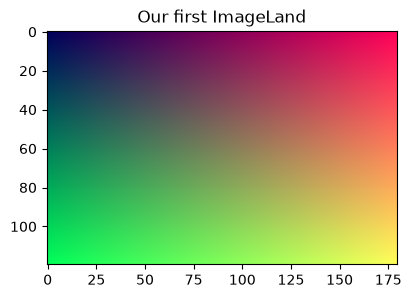

(120, 180) RGB uint8


In [2]:
rows, columns = np.indices((120, 180))
pixels = np.stack((columns / 179, rows / 119, np.full(rows.shape, .35)), axis=-1)
image = ImageLand(pixels)

image.show('Our first ImageLand')
print(image.shape, image.mode, image.get_image().dtype)

### 2. Resize an independent copy

Shapes are `(height, width)`. Points are `(row, column)`. A `SquareMarks` rectangle uses row bounds named minX/maxX and column bounds named minY/maxY for compatibility with the original project.

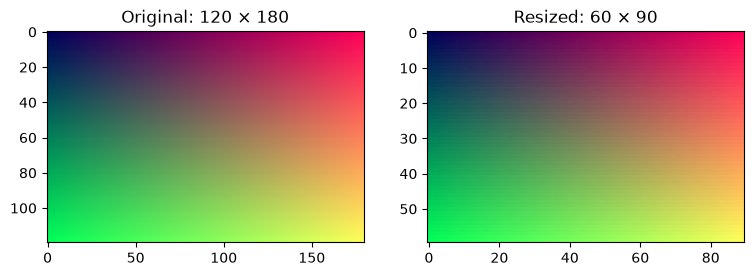

In [3]:
small = image.copy().reshape((60, 90))
fig, axes = plt.subplots(1, 2)
axes[0].imshow(image.get_image()); axes[0].set_title('Original: 120 × 180')
axes[1].imshow(small.get_image()); axes[1].set_title('Resized: 60 × 90')
plt.show()

### 3. Work with alpha and files

`to_rgba()` adds opaque alpha. `to_rgb()` composites onto black. File paths and Pillow images are accepted too; save a result with `PIL.Image.fromarray(image.get_image()).save(...)`.

In [4]:
rgba = image.copy().to_rgba()
print(rgba.mode, rgba.get_image()[0, 0])
help(ImageLand.reshape)

RGBA [  0   0  89 255]
Help on function reshape in module landpy.image_land:

reshape(self, shape, mode=None, save_trace=False)
    Resize to (height, width); retain mode unless RGB/RGBA is specified.



## Checks

In [5]:
assert image.shape == (120, 180)
assert small.shape == (60, 90)
assert rgba.get_image().dtype == np.uint8
assert np.all(rgba.get_image()[..., 3] == 255)
assert image.mode == 'RGB'

## Next steps

Continue with tutorial 2 in the [tutorial index](https://github.com/bateni1380/landpy/tree/master/tutorials).